In [2]:
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
from xgboost import XGBClassifier
from sklearn.datasets import make_classification, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss
import matplotlib.pyplot as plt

In [3]:
X, y = make_classification(
    n_samples=250_000,
    n_features=50,
    n_informative=30,
    random_state=42
)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f"Train hajmi: {X_train.shape}, Valid hajmi: {X_valid.shape}")
# bu yerda dataset generatsiya qildik

Train hajmi: (175000, 50), Valid hajmi: (37500, 50)


In [5]:
def measure(model, name="Model"):
    t = time.perf_counter()
    model.fit(X_train, y_train)
    sec = time.perf_counter() - t

    p = model.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(y_valid, p)
    print(f"[{name}] Vaqt: {sec:.2f} s | Valid AUC: {auc:.4f}")
    return round(sec, 2), round(auc, 4)

results = {}

In [8]:
# 1. XGBoost hist
xgb_hist = XGBClassifier(tree_method="hist", n_estimators=100, random_state=42)
results['XGBoost hist'] = measure(xgb_hist, "XGBoost (hist)")

# 2. LightGBM
lgb_model = lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
results['LightGBM'] = measure(lgb_model, "LightGBM")

[XGBoost (hist)] Vaqt: 7.94 s | Valid AUC: 0.9929


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] Vaqt: 10.34 s | Valid AUC: 0.9883


In [10]:
X_small, y_small = X[:50_000], y[:50_000]
X_tr_s, X_va_s, y_tr_s, y_va_s = train_test_split(X_small, y_small, test_size=0.2, random_state=42)

# exact
t = time.perf_counter()
xgb_exact = XGBClassifier(tree_method="exact", n_estimators=100, random_state=42)
xgb_exact.fit(X_tr_s, y_tr_s)
exact_time = time.perf_counter() - t

# hist
t = time.perf_counter()
xgb_hist_s = XGBClassifier(tree_method="hist", n_estimators=100, random_state=42)
xgb_hist_s.fit(X_tr_s, y_tr_s)
hist_time = time.perf_counter() - t

print(f"50k qatorda Exact vaqt: {exact_time:.2f} s")
print(f"50k qatorda Hist vaqt: {hist_time:.2f} s")
print(f"Tezlik farqi: {exact_time / hist_time:.1f} marta tezroq!")
results['XGB exact (50k)'] = (round(exact_time, 2), "N/A")

50k qatorda Exact vaqt: 48.66 s
50k qatorda Hist vaqt: 8.63 s
Tezlik farqi: 5.6 marta tezroq!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


num_leaves=  4 | Train Logloss: 0.4112 | Valid Logloss: 0.4147


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


num_leaves= 16 | Train Logloss: 0.2189 | Valid Logloss: 0.2289


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


num_leaves= 64 | Train Logloss: 0.1028 | Valid Logloss: 0.1213


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


num_leaves=256 | Train Logloss: 0.0388 | Valid Logloss: 0.0813


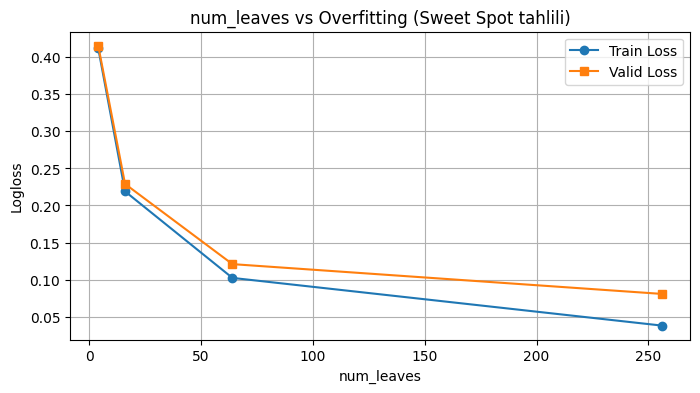

In [11]:
leaves_list = [4, 16, 64, 256]
train_losses = []
valid_losses = []

for nl in leaves_list:
    clf = lgb.LGBMClassifier(num_leaves=nl, n_estimators=100, random_state=42, verbose=-1)
    clf.fit(X_train, y_train)

    p_train = clf.predict_proba(X_train)
    p_valid = clf.predict_proba(X_valid)

    tr_loss = log_loss(y_train, p_train)
    va_loss = log_loss(y_valid, p_valid)

    train_losses.append(tr_loss)
    valid_losses.append(va_loss)
    print(f"num_leaves={nl:3d} | Train Logloss: {tr_loss:.4f} | Valid Logloss: {va_loss:.4f}")

# Grafik
plt.figure(figsize=(8, 4))
plt.plot(leaves_list, train_losses, marker='o', label='Train Loss')
plt.plot(leaves_list, valid_losses, marker='s', label='Valid Loss')
plt.xlabel('num_leaves')
plt.ylabel('Logloss')
plt.title('num_leaves vs Overfitting (Sweet Spot tahlili)')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
#LightGBM Early stopping
model_early = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbose=-1
)

model_early.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)]
)

print(f"LightGBM Eng yaxshi round: {model_early.best_iteration_}")

# XGBoost lossguide (Leaf-wise XGBoost)
xgb_lossguide = XGBClassifier(
    tree_method="hist",
    grow_policy="lossguide",
    max_leaves=31,
    n_estimators=100,
    random_state=42
)
results['XGBoost lossguide'] = measure(xgb_lossguide, "XGBoost lossguide")

Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.256993
[200]	valid_0's binary_logloss: 0.167271
[300]	valid_0's binary_logloss: 0.132004
[400]	valid_0's binary_logloss: 0.115203
[500]	valid_0's binary_logloss: 0.106871
[600]	valid_0's binary_logloss: 0.1007
[700]	valid_0's binary_logloss: 0.0956166
[800]	valid_0's binary_logloss: 0.0921674
[900]	valid_0's binary_logloss: 0.088496
[1000]	valid_0's binary_logloss: 0.0847023
Did not meet early stopping. Best iteration is:
[1000]	valid_0's binary_logloss: 0.0847023
LightGBM Eng yaxshi round: 1000
[XGBoost lossguide] Vaqt: 15.81 s | Valid AUC: 0.9923


In [15]:
summary_df = pd.DataFrame(results, index=['Vaqt', 'AUC']).T
print(summary_df)

                    Vaqt     AUC
XGBoost hist        7.94  0.9929
LightGBM           10.34  0.9883
XGB exact (50k)    48.66     N/A
XGBoost lossguide  15.81  0.9923
